# Reaction and diffusion solvers
Generic ODE solvers behind the kinetic model.

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from kinetic_model.core.reactor import Reaction
from kinetic_model.core.diffusion import Reaction_Diffusion

def plot(df, title):
    d = df.copy(); d['time'] = d.index
    sns.lineplot(data=d.melt('time', var_name='species', value_name='conc'), x='time', y='conc', hue='species').set_title(title)
    plt.show()

## Reactions
`['A + B -> C', k]` irreversible, `['A <-> B', kf, kb]` reversible.

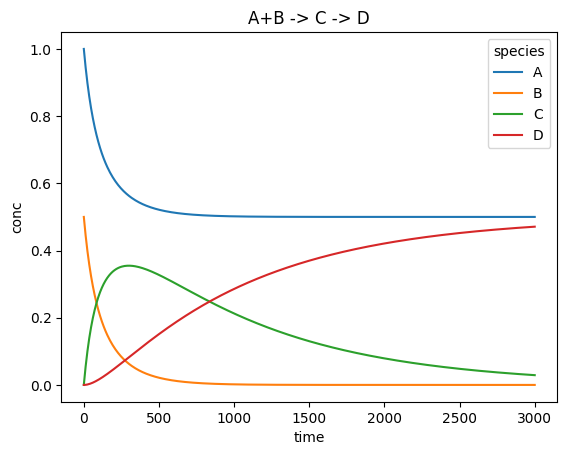

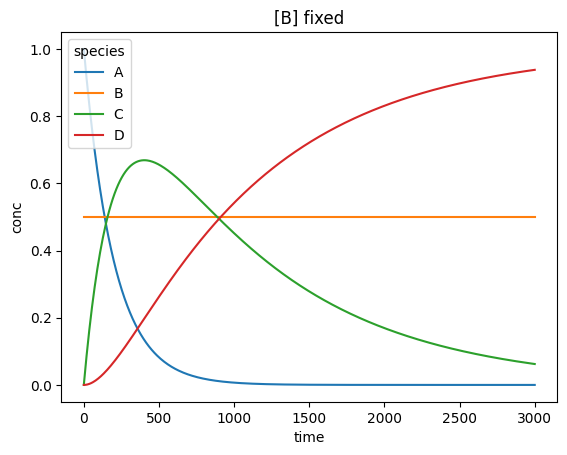

In [2]:
t = np.linspace(0, 3000, 500)
rx = [['A + B -> C', 1e-2], ['C -> D', 1e-3]]
plot(Reaction(rx).solve({'A': 1.0, 'B': 0.5, 'C': 0.0, 'D': 0.0}, t), 'A+B -> C -> D')
plot(Reaction(rx, fixed_concentrations=['B']).solve({'A': 1.0, 'B': 0.5, 'C': 0.0, 'D': 0.0}, t), '[B] fixed')

## Diffusion between compartments
`X@A <D> X@B`: species X in compartment A/B; `capacity` weights the compartments.

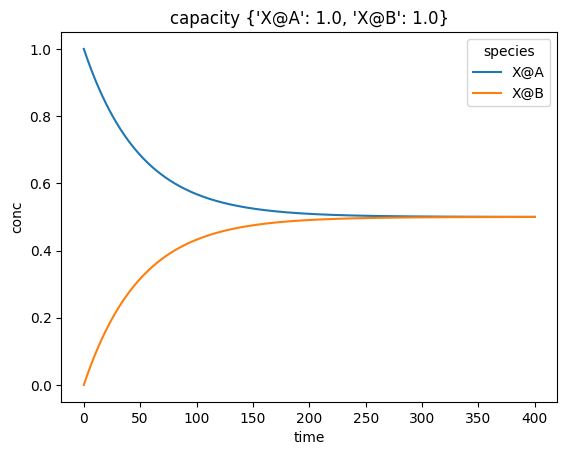

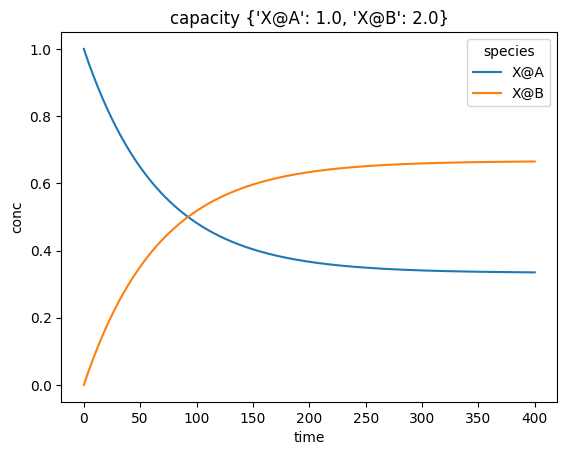

In [3]:
t = np.linspace(0, 400, 500)
rx = [['X@A <D> X@B', 1e-2, 1e-2]]
for cap in ({'X@A': 1.0, 'X@B': 1.0}, {'X@A': 1.0, 'X@B': 2.0}):
    plot(Reaction_Diffusion(reactions=rx, capacity=cap).solve({'X@A': 1.0, 'X@B': 0.0}, t), f'capacity {cap}')

## Reaction + diffusion

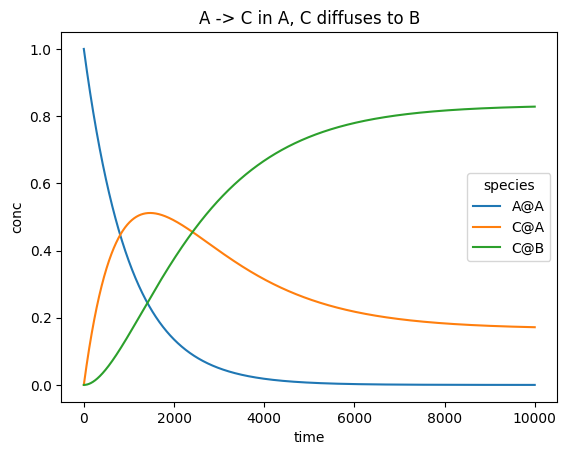

In [4]:
rx = [['A@A -> C@A', 1e-3], ['C@A <D> C@B', 5e-4, 2e-4]]
cap = {'A@A': 1.0, 'C@A': 1.0, 'C@B': 2.0}
plot(Reaction_Diffusion(reactions=rx, capacity=cap).solve({'A@A': 1.0, 'C@A': 0.0, 'C@B': 0.0}, np.linspace(0, 1e4, 2000)),
     'A -> C in A, C diffuses to B')